# Deterministic vs stochastic world models

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/comparisons/deterministic_vs_stochastic.ipynb)

Does a world model that predicts a distribution over futures plan better, and does it know how far off it is? Three models with the same encoder and the same predictor size learn PLDM's Two-Rooms from the same pixels:
- **[LeWM](../action/lewm.ipynb)**: one next embedding per step, a point forecast;
- **[Flow-JEPA](../action/flowjepa.ipynb)**: turns Gaussian noise into the next 8 embeddings by flow matching, so each draw is one future;
- **[Variational JEPA](../action/varjepa.ipynb)**: a Gaussian over the next embedding, unrolled by sampling.

Two questions: how often each reaches goals with the same planner, and whether the spread of its imagined futures matches its actual error on held-out episodes (calibration).

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import time
from functools import partial

import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, metrics, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import FlowJEPA, LeWM, VariationalJEPA
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
H = 8  # steps imagined, for planning and for calibration

## Data
A point wanders through two rooms joined by a door, keeping its previous action 80% of the time: 1024 episodes of 65 steps, no rewards, no expert. A second set of 256 episodes, never trained on, scores the predictions.

In [3]:
data = TwoRooms(batch_size=1024, device=device).collect(65, generator=torch.Generator().manual_seed(0))
held_out = TwoRooms(batch_size=256, device=device).collect(65, generator=torch.Generator().manual_seed(5))


def loader(window):
    return DataLoader(TrajectoryDataset(data, window=window), batch_size=128, shuffle=True, drop_last=True)

## Three models, one size
The same ViT encoder and a predictor of 4 blocks of width 128 for each, with the same SIGReg weight. LeWM and Variational JEPA see 3 frames and predict the next one; Flow-JEPA sees one frame and samples the next 8 embeddings together, as many as the planner imagines.

In [4]:
def encoder():
    return CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)


size = dict(embed_dim=128, depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512, lamb=0.05)
models = {
    "LeWM": LeWM(encoder(), action_dim=2, history=3, **size),
    "Flow-JEPA": FlowJEPA(encoder(), action_dim=2, num_preds=H, **size),
    "Variational JEPA": VariationalJEPA(encoder(), action_dim=2, history=3, **size),
}
for name, model in models.items():
    print(f"{name:18s} {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:5.2f}M trainable parameters")

LeWM                2.34M trainable parameters
Flow-JEPA           2.37M trainable parameters
Variational JEPA    2.42M trainable parameters


## Train
10 epochs each on the same episodes, with each model's own recipe: next-embedding MSE for LeWM, flow matching on windows of 9 frames for Flow-JEPA, and for Variational JEPA the likelihood of targets drawn around an EMA target encoder.

LeWM                 5.2 min


Flow-JEPA           10.2 min


Variational JEPA     6.1 min


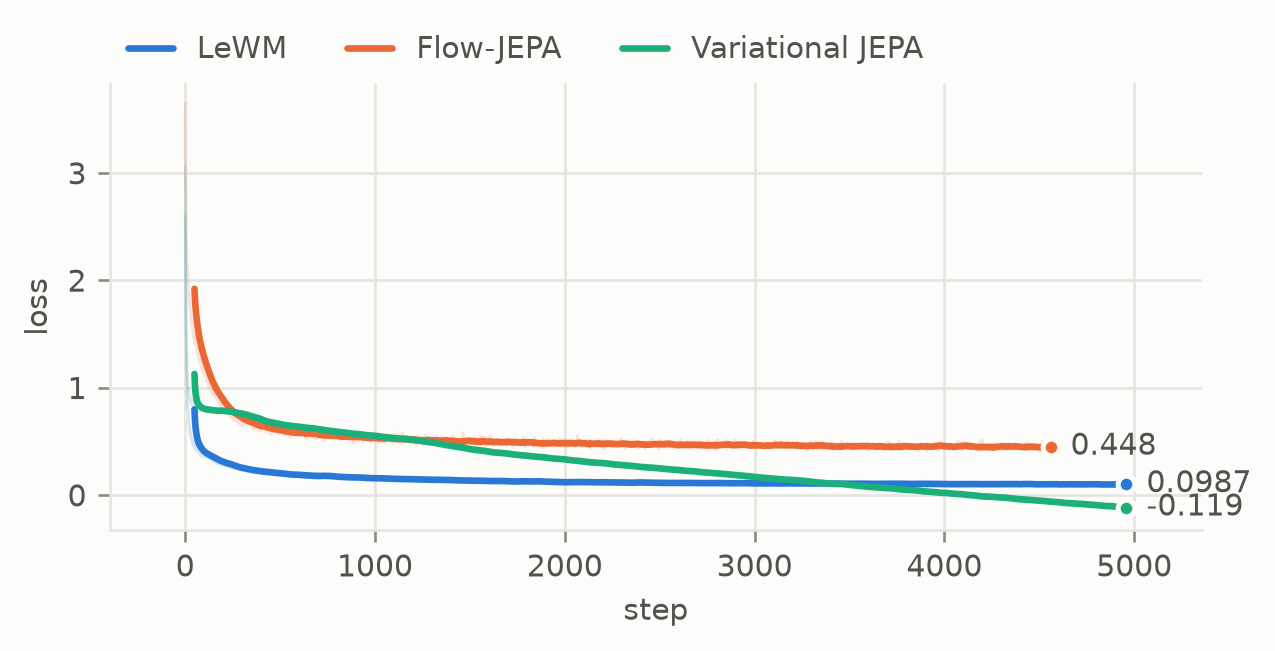

In [5]:
vjepa = models["Variational JEPA"]
recipes = {
    "LeWM": dict(window=4),
    "Flow-JEPA": dict(window=H + 1, lr=3e-4, clip=1.0),
    "Variational JEPA": dict(window=4, lr=3e-4, step=lambda: vjepa.update_target(0.99)),
}
logs, minutes = {}, {}
for name, model in models.items():
    recipe = dict(recipes[name])
    tic = time.time()
    logs[name] = fit(model.to(device), loader(recipe.pop("window")), epochs=10, **recipe)["loss"]
    minutes[name] = (time.time() - tic) / 60
    print(f"{name:18s} {minutes[name]:5.1f} min")
plots.curves(logs, smooth=50, logy=False)

## Calibration of imagined futures
From the first frame of 1024 held-out windows and the 8 actions actually taken, each model imagines the next 8 embeddings, and each stochastic model draws 32 futures. The truth is the encoding of the frames that followed (for Variational JEPA, its EMA target encoder, which is what it learns to predict). Each model has its own latent space, so errors are measured in units of the spread of its own embeddings.

LeWM gives a point forecast: zero spread, and its CRPS and energy score reduce to its absolute and Euclidean errors, the reference the stochastic models should beat. Flow-JEPA's point forecast is the mean of its samples; Variational JEPA's is its predictive mean unrolled.

In [6]:
S = 32
windows = DataLoader(TrajectoryDataset(held_out, window=H + 1), batch_size=1024, shuffle=True, generator=torch.Generator().manual_seed(0))
batch = next(iter(windows))


@torch.no_grad()
def imagine(name, model, pixels, actions, chunk=128):
    """Point forecast (B, H, D), S futures (B, S, H, D) and the truth (B, H, D), in units of the embeddings' spread."""
    torch.manual_seed(0)
    points, futures, truth = [], [], []
    for px, act in zip(pixels.split(chunk), actions.split(chunk)):
        z = model.encode(px)
        target = model.encode(px, model.target_encoder) if name == "Variational JEPA" else z
        if name == "LeWM":
            point = model.rollout(z[:, :1], act[:, :H])[:, 1:]
            samples = point[:, None]
        else:
            samples = model.sample(z[:, :1], act[:, :H], num_samples=S)[:, :, 1:]
            point = samples.mean(1) if name == "Flow-JEPA" else model.rollout(z[:, :1], act[:, :H])[:, 1:]
        points.append(point), futures.append(samples), truth.append(target[:, 1:])
    points, futures, truth = torch.cat(points), torch.cat(futures), torch.cat(truth)
    scale = truth.flatten(0, 1).var(0).mean().sqrt()
    return points / scale, futures / scale, truth / scale


forecasts = {name: imagine(name, model, batch["pixels"], batch["actions"]) for name, model in models.items()}

The error of each point forecast grows with the horizon. Below it, spread over skill at each step: the root mean variance of the 32 futures over the error of their mean. A calibrated model keeps the ratio near 1 at every step; below 1 it is overconfident, above 1 underconfident.

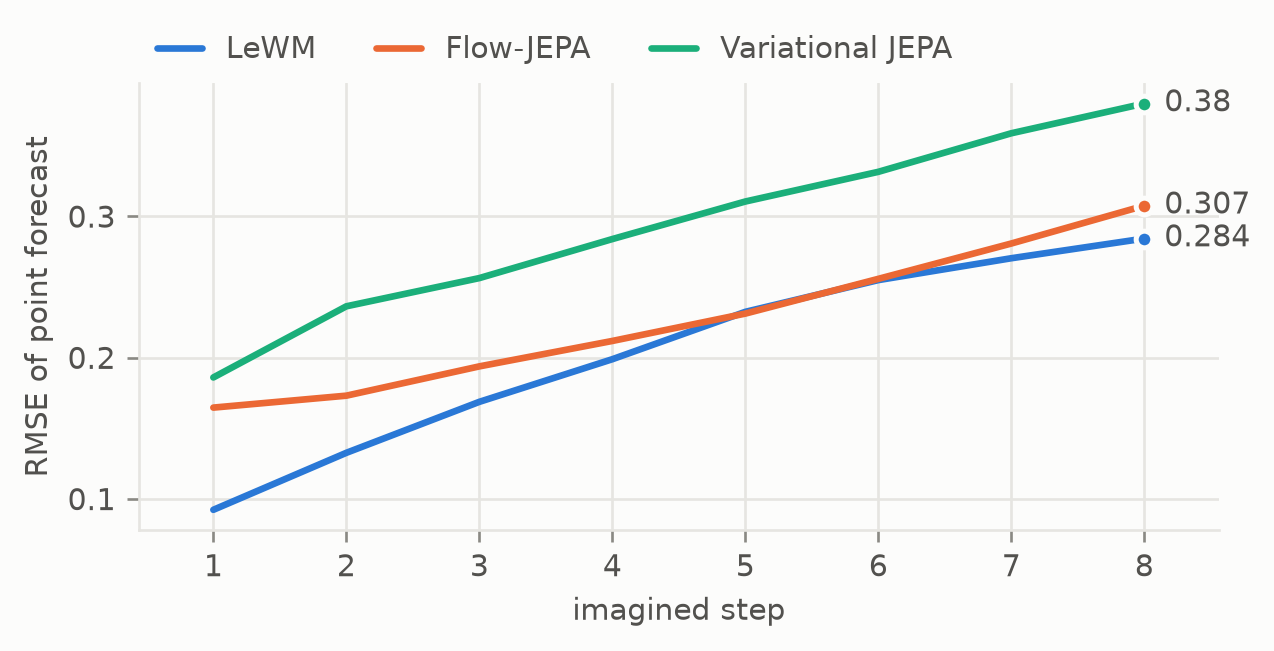

In [7]:
steps = range(1, H + 1)
curves, ratios, table = {}, {}, {}
levels = (0.5, 0.8, 0.9, 0.95)
for name, (point, futures, truth) in forecasts.items():
    spread, skill = metrics.spread_skill(futures, truth, dim=(0, 2))
    point_error = (point - truth).square().mean((0, 2)).sqrt()
    curves[name] = (steps, point_error.tolist())
    if name != "LeWM":
        ratios[name] = (steps, (spread / skill).tolist())
    var = futures.var(1) if futures.size(1) > 1 else None
    table[name] = {
        "RMSE": point_error.mean().item(),
        "spread / skill": (spread / skill).mean().item(),
        **{f"{l:.0%} cov.": c.item() for l, c in zip(levels, metrics.interval_coverage(futures, truth, levels).mean((1, 2, 3)))},
        "CRPS": metrics.crps(futures, truth, fair=True).mean().item(),
        "energy": metrics.energy_score(futures, truth, fair=True).mean().item(),
        "NLL": metrics.gaussian_nll(futures.mean(1), var, truth).mean().item() if var is not None else float("nan"),
    }
plots.curves(curves, smooth=1, logy=False, xlabel="imagined step", ylabel="RMSE of point forecast")

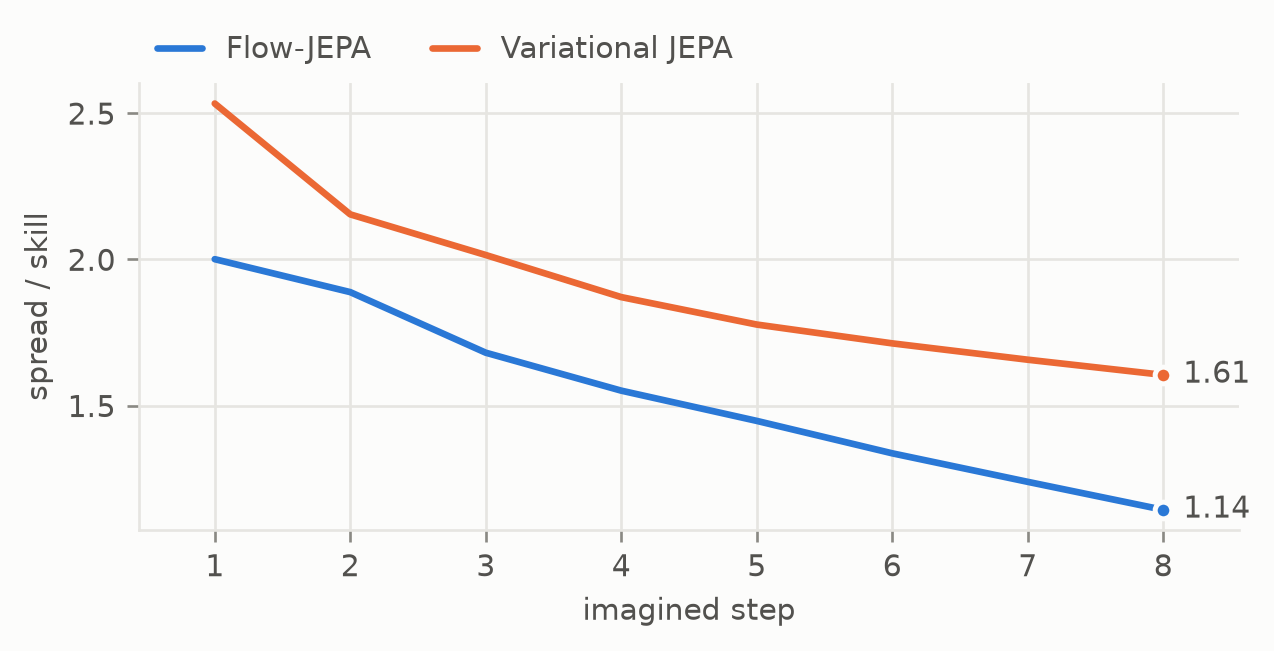

In [8]:
plots.curves(ratios, smooth=1, logy=False, xlabel="imagined step", ylabel="spread / skill")

Coverage of the central intervals of the 32 futures against their nominal level, over all steps and dimensions. The diagonal is perfect calibration; below it the intervals are too narrow.

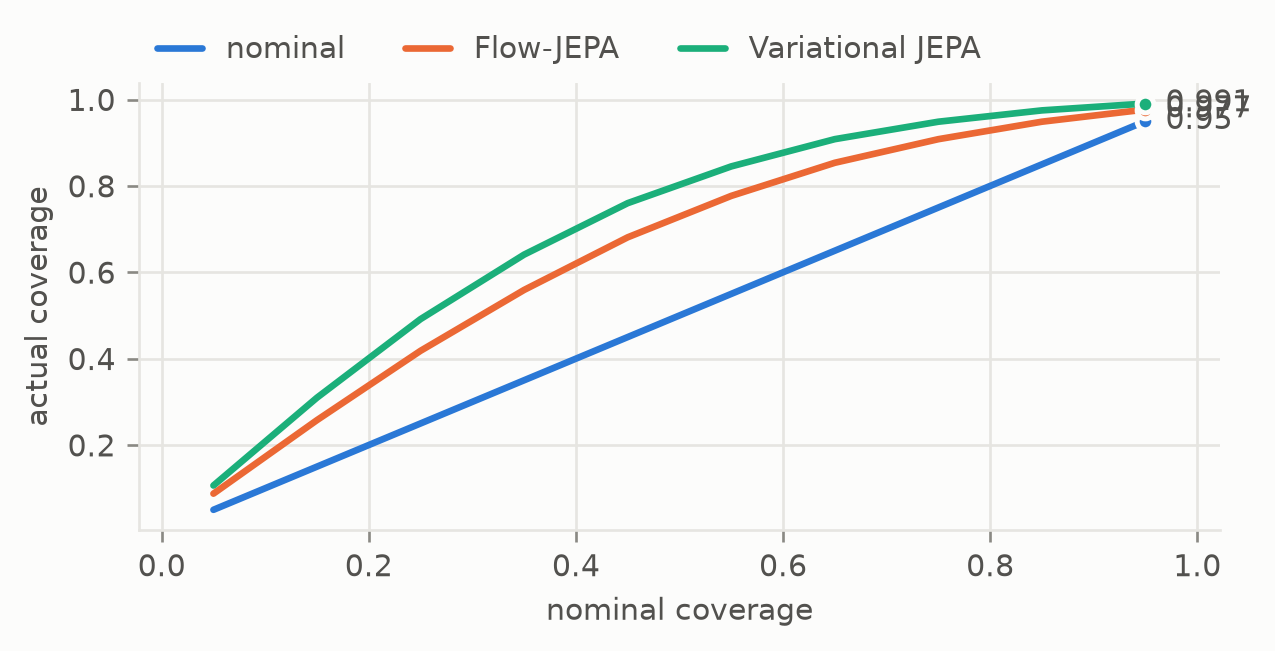

In [9]:
nominal = torch.linspace(0.05, 0.95, 10).tolist()
reliability = {"nominal": (nominal, nominal)}
for name, (point, futures, truth) in forecasts.items():
    if name != "LeWM":
        reliability[name] = (nominal, metrics.interval_coverage(futures, truth, nominal).mean((1, 2, 3)).tolist())
plots.curves(reliability, smooth=1, logy=False, xlabel="nominal coverage", ylabel="actual coverage")

Variational JEPA also gives its one-step Gaussian in closed form, so its first step can be scored without sampling.

In [10]:
with torch.no_grad():
    px, act = batch["pixels"][:256], batch["actions"][:256]
    z, target = vjepa.encode(px[:, :2]), vjepa.encode(px[:, 1:2], vjepa.target_encoder)[:, 0]
    mean, logvar = vjepa.distribution(z[:, :1], act[:, :1])
    mean, var = mean[:, 0], logvar[:, 0].exp()
    scale = target.var(0).mean().sqrt()
    mean, var, target = mean / scale, var / scale**2, target / scale
    half = torch.special.ndtri(torch.tensor(levels, device=device).add(1).div(2))[:, None, None] * var.sqrt()
    cover = ((target - mean).abs() <= half).float().mean((1, 2))
    q_var = vjepa.target_logvar(target * scale).clamp(*vjepa.logvar_range).exp().mean() / scale**2
print("one step, closed form: NLL", f"{metrics.gaussian_nll(mean, var, target).mean():.3f},", "coverage", ", ".join(f"{l:.0%}: {c:.0%}" for l, c in zip(levels, cover)))
print(f"mean predicted variance {var.mean():.3g}, mean squared error {(mean - target).square().mean():.3g}, variance of the target distribution q {q_var:.3g}")

one step, closed form: NLL 0.246, coverage 50%: 96%, 80%: 99%, 90%: 100%, 95%: 100%
mean predicted variance 0.262, mean squared error 0.0308, variance of the target distribution q 0.225


All 8 steps together, errors in units of each model's embedding spread (lower is better, except coverage, which should match its level, and spread / skill, which should be 1):

In [11]:
columns = list(table["LeWM"])
print(f"{'':18s}" + "".join(f"{c:>15s}" for c in columns))
for name, row in table.items():
    print(f"{name:18s}" + "".join(f"{row[c]:>15.3f}" for c in columns))

                             RMSE spread / skill       50% cov.       80% cov.       90% cov.       95% cov.           CRPS         energy            NLL
LeWM                        0.204          0.000          0.000          0.000          0.000          0.000          0.121          1.705            nan
Flow-JEPA                   0.227          1.536          0.732          0.930          0.964          0.977          0.117          1.706         -0.098
Variational JEPA            0.293          1.916          0.807          0.963          0.984          0.991          0.192          2.747          0.495


## Plan toward goal images
The same CEM for every model: 8 steps ahead, 128 candidates, 16 elites, 5 iterations, scoring the distance to the goal along the whole imagined path, replanning after every step. Flow-JEPA scores each candidate on one sampled future; Variational JEPA plans once on its mean (the paper's MAP plan) and once on sampled futures. 64 tasks with the goal in the same room and 64 in the other room, 60 steps each; an episode succeeds when it comes within 0.1 of the goal at any step.

In [12]:
cem = CEM(horizon=H, action_dim=2, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1), objective="path")
planners = {
    "LeWM": ("LeWM", cem),
    "Flow-JEPA": ("Flow-JEPA", cem),
    "Var. JEPA, mean": ("Variational JEPA", cem),
    "Var. JEPA, samples": ("Variational JEPA", partial(cem, sample=True)),
}
env = TwoRooms(batch_size=64, device=device)
results = {}
for task, same_room in [("same room", True), ("other room", False)]:
    start, goal = env.tasks(torch.Generator().manual_seed(1), same_room=same_room)
    goal_images = env.render(goal)
    policies = {label: evaluation.goal_policy(models[name], planner, goal_images) for label, (name, planner) in planners.items()}
    policies["random actions"] = evaluation.random_policy(env)
    results[task] = evaluation.goal_reaching(env, policies, start, goal, steps=60, success="reached")
    print(f"== {task}\n{results[task]}")

== same room
                              success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM                   67% [55%, 77%]      67%    1.79          0.0277     0.842   0.139       0.393      1e+03
Flow-JEPA              95% [87%, 98%]      95%    3.18          0.0419     0.861   0.159       0.505   3.38e+03
Var. JEPA, mean        83% [72%, 90%]      83%     2.7          0.0213     0.915   0.198       0.349      1e+03
Var. JEPA, samples     83% [72%, 90%]      83%    2.68          0.0188     0.916   0.205       0.348   1.02e+03
random actions         55% [43%, 66%]      59%    15.4           0.354    -0.166  0.0351        1.04     0.0137


== other room
                              success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM                   23% [15%, 35%]      23%    6.73           0.516    0.0409  0.0615       0.349      1e+03
Flow-JEPA              64% [52%, 75%]      64%    11.9          0.0602     0.877   0.184       0.504   3.39e+03
Var. JEPA, mean         11% [5%, 21%]      11%      12           0.733   -0.0905  0.0358        0.32      1e+03
Var. JEPA, samples       9% [4%, 19%]       9%       7           0.734    -0.139  0.0251       0.368   1.02e+03
random actions           8% [3%, 17%]       8%    39.8           0.561    0.0479 0.00984        1.04     0.0134


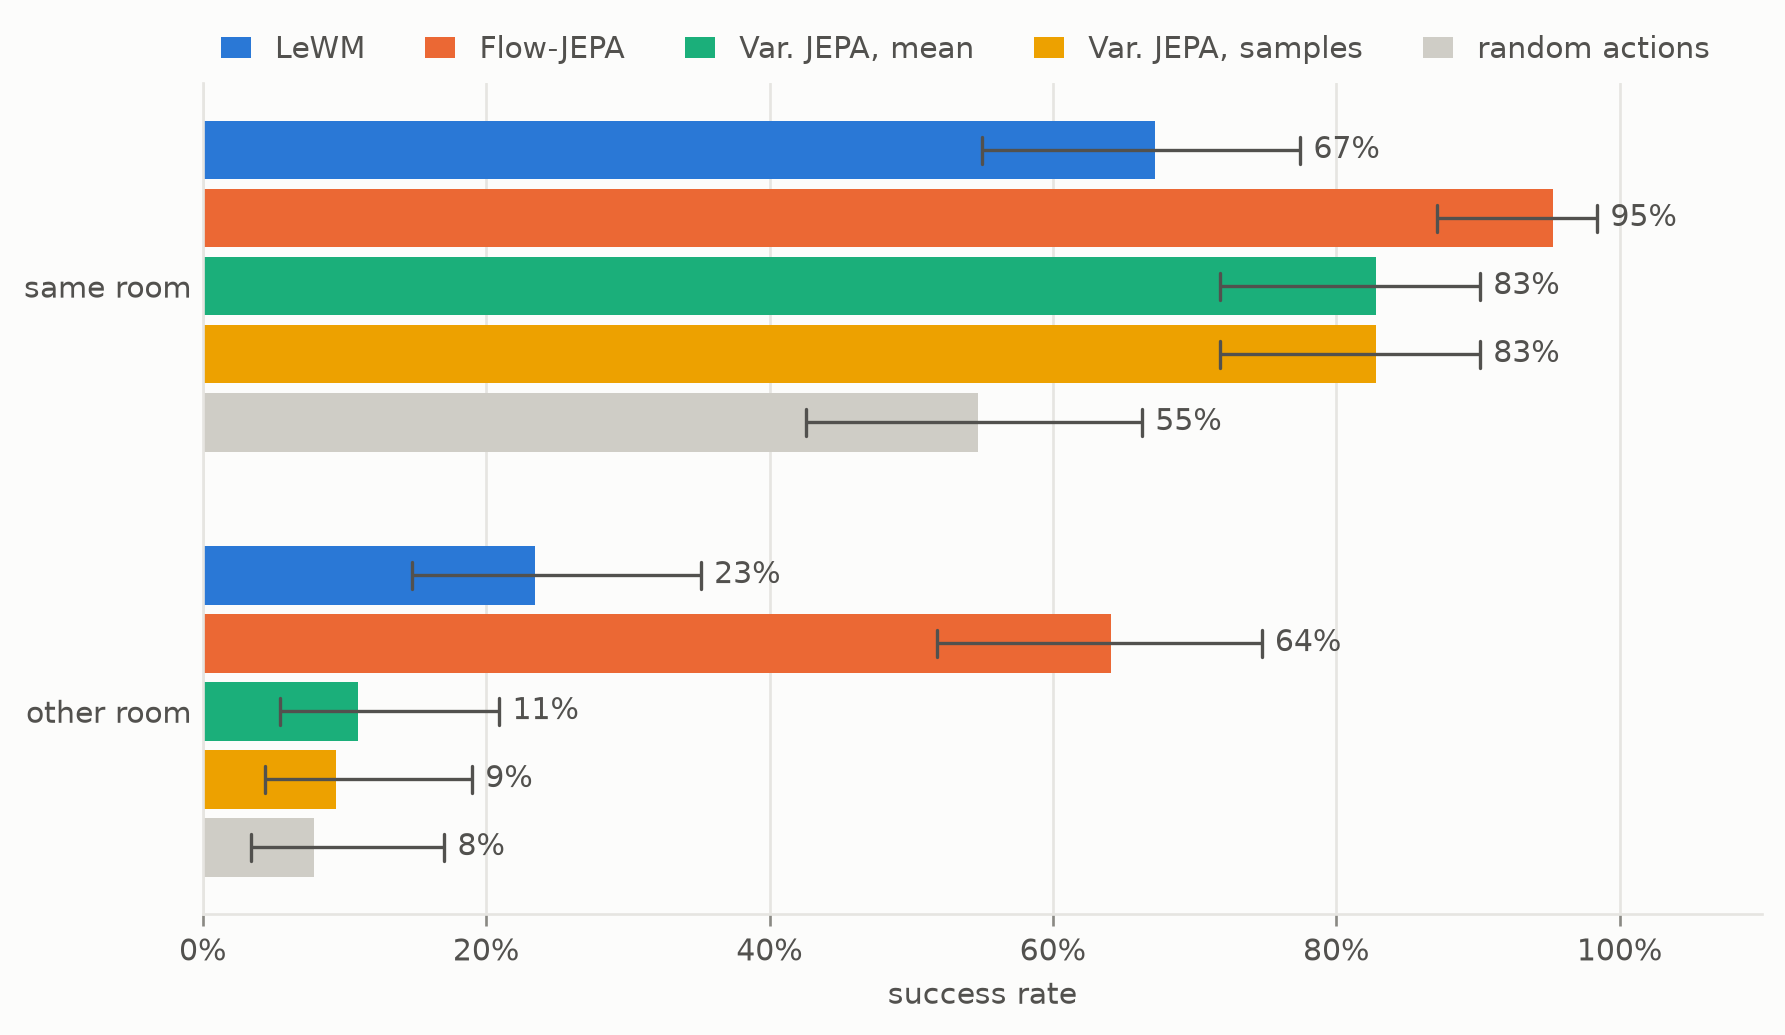

In [13]:
plots.bars({task: r.intervals() for task, r in results.items()}, xlabel="success rate", baseline="random actions", size=(7.5, 4.2))

## Summary
Success, planning time and calibration side by side:

In [14]:
print(f"{'':20s}{'same room':>20s}{'other room':>20s}{'plan ms':>9s}")
for label in [*planners, "random actions"]:
    same, other = (results[t].intervals()[label] for t in ("same room", "other room"))
    print(f"{label:20s}{same!s:>20}{other!s:>20}{1000 * results['other room'].seconds[label]:9.0f}")

                               same room          other room  plan ms
LeWM                      67% [55%, 77%]      23% [15%, 35%]     1000
Flow-JEPA                 95% [87%, 98%]      64% [52%, 75%]     3387
Var. JEPA, mean           83% [72%, 90%]       11% [5%, 21%]     1002
Var. JEPA, samples        83% [72%, 90%]        9% [4%, 19%]     1018
random actions            55% [43%, 66%]        8% [3%, 17%]        0


Flow-JEPA plans best, by far on the long tasks (64% through the door against 23% for LeWM), at about three times LeWM's planning time. That is not only because it samples: it is also the one model trained to predict all 8 imagined steps at once, from one frame, so the planner scores futures from the objective the model learned on, where LeWM and Variational JEPA unroll one-step predictions on their own outputs. Variational JEPA does better than LeWM in the same room but not across the wall, where it does no better than random actions, and planning on its samples gives the same results as on its mean, as its paper expects when the noise hardly depends on the action.

Neither stochastic model is overconfident; both are underconfident. Their futures spread more than their errors (spread / skill above 1, intervals that cover more than their level), most at the first step, and the gap closes with the horizon, where the error catches up with a spread that barely grows. Variational JEPA's predicted variance mostly matches the variance of its own target distribution, about 8 times its actual squared error against the target mean, which is what it is trained to cover. Per dimension (CRPS), Flow-JEPA's 32 futures score slightly better than LeWM's point forecast, and as a whole vector (energy score) they tie; LeWM's single prediction is the most accurate point forecast at the first steps. At this scale, a distribution over futures did not buy calibration, but Flow-JEPA's joint multi-step prediction did buy planning.